In [19]:
import os, glob, time
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import jax, jax.numpy as jnp
import optax
import pickle

jax.config.update("jax_enable_x64", False)
print(jax.devices())

DATA_ROOT = os.environ.get("DATA_ROOT", os.path.expanduser("~/private/Dsc-180/"))
OUT = "~/private/Dsc-180/output"
TRAIN = ["ssp126", "ssp370", "ssp585", "historical", "hist-GHG", "hist-aer"]
TEST = "ssp245"

N_SO2_PC, N_BC_PC = 5, 5     # input compression
N_TAS_PC = 20                # output patterns
HIDDEN = (64, 64)
STEPS, LR, WD = 3000, 1e-3, 1e-4
SEEDS = [0, 1, 2, 3, 4]
STEPS, LR, WD = 3000, 1e-3, 1e-4
START, END = 2080, 2100      # ClimateBench scoring window

BEST_WEEK3_TAS_TOTAL = 0.284

[CpuDevice(id=0)]


In [16]:
private/Dsc-180/output


'.'

In [6]:
def find(name):
    hits = glob.glob(os.path.join(DATA_ROOT, "**", name), recursive=True)
    if not hits:
        raise FileNotFoundError(f"{name} not found under {DATA_ROOT}")
    return hits[0]

def load(scenario):
    """Inputs and ensemble-mean tas for one scenario, on the years both files share."""
    X = xr.open_dataset(find(f"inputs_{scenario}.nc"))
    Y = xr.open_dataset(find(f"outputs_{scenario}.nc"))
    if "member" in Y.dims:
        Y = Y.mean("member")
    years = np.intersect1d(X.time.values, Y.time.values)
    X, Y = X.sel(time=years), Y.sel(time=years)
    return {
        "years": years,
        "co2": X["CO2"].values.astype(np.float32),                        # (T,)
        "ch4": X["CH4"].values.astype(np.float32),                        # (T,)
        "so2": X["SO2"].transpose("time", ...).values.astype(np.float32), # (T, lat, lon)
        "bc":  X["BC"].transpose("time", ...).values.astype(np.float32),  # (T, lat, lon)
        "tas": Y["tas"].transpose("time", ...).values.astype(np.float32), # (T, lat, lon)
        "lat": Y["lat"].values,
        "lon": Y["lon"].values,
    }

data = {}
for s in TRAIN + [TEST]:
    try:
        data[s] = load(s)
        d = data[s]
        print(f"{s:11s} years {d['years'][0]}-{d['years'][-1]} ({len(d['years'])}) | tas {d['tas'].shape}")
    except FileNotFoundError as e:
        print("skipping:", e)
TRAIN = [s for s in TRAIN if s in data]
assert TEST in data, "need the ssp245 test files"

lat, lon = data[TEST]["lat"], data[TEST]["lon"]
NLAT, NLON = len(lat), len(lon)
area_w = np.cos(np.deg2rad(lat))[:, None] * np.ones((1, NLON))
area_w = jnp.asarray(area_w / area_w.mean(), dtype=jnp.float32)      # (lat, lon), mean 1

ssp126      years 2015-2100 (86) | tas (86, 96, 144)
ssp370      years 2015-2100 (86) | tas (86, 96, 144)
ssp585      years 2015-2100 (86) | tas (86, 96, 144)
historical  years 1850-2014 (165) | tas (165, 96, 144)
hist-GHG    years 1850-2014 (165) | tas (165, 96, 144)
hist-aer    years 1850-2014 (165) | tas (165, 96, 144)
ssp245      years 2015-2100 (86) | tas (86, 96, 144)


In [7]:
def stack(key):
    return np.concatenate([data[s][key] for s in TRAIN], axis=0)

def pca(maps, k):
    """Mean map and the first k patterns (k, lat*lon) of a stack of maps."""
    A = maps.reshape(len(maps), -1)
    mean = A.mean(0)
    _, svals, Vt = np.linalg.svd(A - mean, full_matrices=False)
    explained = (svals[:k] ** 2).sum() / (svals ** 2).sum()
    return mean.astype(np.float32), Vt[:k].astype(np.float32), explained

so2_mean, so2_pcs, ev = pca(stack("so2"), N_SO2_PC); print(f"SO2: {N_SO2_PC} PCs explain {ev:.1%}")
bc_mean,  bc_pcs,  ev = pca(stack("bc"),  N_BC_PC);  print(f"BC:  {N_BC_PC} PCs explain {ev:.1%}")
tas_mean, tas_pcs, ev = pca(stack("tas"), N_TAS_PC); print(f"tas: {N_TAS_PC} PCs explain {ev:.1%}")

# everything emulate() needs, as fixed jnp arrays
PRE = {k: jnp.asarray(v) for k, v in dict(so2_mean=so2_mean, so2_pcs=so2_pcs,
                                          bc_mean=bc_mean, bc_pcs=bc_pcs,
                                          tas_mean=tas_mean, tas_pcs=tas_pcs).items()}

C_train = (stack("tas").reshape(-1, NLAT * NLON) - tas_mean) @ tas_pcs.T     # (N, N_TAS_PC)
PRE["c_std"] = jnp.asarray(C_train.std(0) + 1e-8)
print("pattern-weight std (first 5):", np.asarray(PRE["c_std"][:5]).round(1))

def features(co2, ch4, so2, bc, pre=None):
    """(T,), (T,), (T,lat,lon), (T,lat,lon) -> raw features (T, 2 + N_SO2_PC + N_BC_PC)."""
    pre = PRE if pre is None else pre
    T = co2.shape[0]
    so2_f = (so2.reshape(T, -1) - pre["so2_mean"]) @ pre["so2_pcs"].T
    bc_f  = (bc.reshape(T, -1)  - pre["bc_mean"])  @ pre["bc_pcs"].T
    return jnp.concatenate([co2[:, None], ch4[:, None], so2_f, bc_f], axis=1)

# standardization constants from the training features
F_train = np.concatenate([np.asarray(features(*(jnp.asarray(data[s][k]) for k in ["co2", "ch4", "so2", "bc"])))
                          for s in TRAIN])
PRE["f_mean"] = jnp.asarray(F_train.mean(0))
PRE["f_std"] = jnp.asarray(F_train.std(0) + 1e-8)
print("feature matrix:", F_train.shape)

SO2: 5 PCs explain 94.9%
BC:  5 PCs explain 98.1%
tas: 20 PCs explain 96.5%
pattern-weight std (first 5): [159.5  24.7  19.2  16.4  15.9]
feature matrix: (753, 12)


In [8]:
def init_mlp(key, sizes):
    params = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        key, sub = jax.random.split(key)
        params.append({"W": jax.random.normal(sub, (n_in, n_out)) * jnp.sqrt(1.0 / n_in),
                       "b": jnp.zeros(n_out)})
    params.append({"W": jnp.zeros((sizes[0], sizes[-1])), "b": jnp.zeros(sizes[-1])})  # linear shortcut
    return params

def mlp(params, x):
    *layers, skip = params
    h = x
    for layer in layers[:-1]:
        h = jnp.tanh(h @ layer["W"] + layer["b"])
    return h @ layers[-1]["W"] + layers[-1]["b"] + x @ skip["W"] + skip["b"]

def predict(params, co2, ch4, so2, bc, pre=None):
    """One network: inputs -> tas maps (T, lat, lon)."""
    pre = PRE if pre is None else pre
    x = (features(co2, ch4, so2, bc, pre) - pre["f_mean"]) / pre["f_std"]
    coeffs = mlp(params, x) * pre["c_std"]                                   # (T, N_TAS_PC)
    maps = pre["tas_mean"] + coeffs @ pre["tas_pcs"]         # (T, lat*lon)
    return maps.reshape(co2.shape[0], NLAT, NLON)

# training arrays (all training scenarios concatenated along time)
Xtr = {k: jnp.asarray(stack(k)) for k in ["co2", "ch4", "so2", "bc"]}
Ytr = jnp.asarray(stack("tas"))

def loss_fn(params):
    pred = predict(params, Xtr["co2"], Xtr["ch4"], Xtr["so2"], Xtr["bc"])
    return jnp.mean(area_w * (pred - Ytr) ** 2)              # latitude-weighted MSE (K²)

seed 0: final train loss 0.1887 K² (191.4 s)
seed 1: final train loss 0.1895 K² (185.6 s)
seed 2: final train loss 0.1916 K² (183.5 s)
seed 3: final train loss 0.1871 K² (189.6 s)
seed 4: final train loss 0.1914 K² (189.5 s)


Text(0.5, 1.0, 'Training loss')

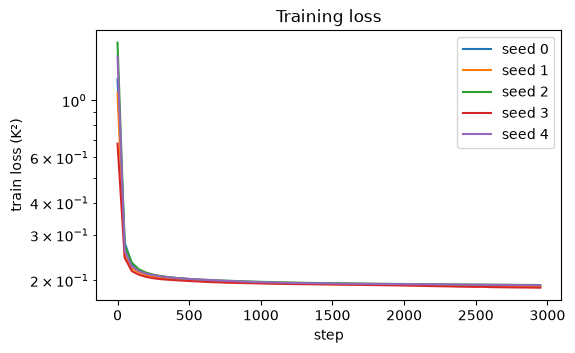

In [9]:
sizes = [int(PRE["f_mean"].shape[0]), *HIDDEN, N_TAS_PC]
opt = optax.adamw(LR, weight_decay=WD)

@jax.jit
def step(params, opt_state):
    loss, grads = jax.value_and_grad(loss_fn)(params)
    updates, opt_state = opt.update(grads, opt_state, params)
    return optax.apply_updates(params, updates), opt_state, loss

trained, histories = [], {}
for seed in SEEDS:
    params = init_mlp(jax.random.key(seed), sizes)
    opt_state = opt.init(params)
    t0, hist = time.time(), []
    for i in range(STEPS):
        params, opt_state, loss = step(params, opt_state)
        if i % 50 == 0:
            hist.append(float(loss))
    trained.append(params)
    histories[seed] = hist
    print(f"seed {seed}: final train loss {float(loss):.4f} K² ({time.time() - t0:.1f} s)")

plt.figure(figsize=(6, 3.5))
for seed, h in histories.items():
    plt.semilogy(np.arange(len(h)) * 50, h, label=f"seed {seed}")
plt.xlabel("step"); plt.ylabel("train loss (K²)"); plt.legend(); plt.title("Training loss")

In [10]:
STACKED = jax.tree_util.tree_map(lambda *p: jnp.stack(p), *trained)   # each leaf: (n_seeds, ...)
PRE_FROZEN = dict(PRE)                                                   # snapshot of the preprocessing

@jax.jit
def emulate(co2, ch4, so2, bc):
    """ClimateBench inputs for one scenario -> tas, shape (years, lat, lon)."""
    per_seed = jax.vmap(lambda p: predict(p, co2, ch4, so2, bc, PRE_FROZEN))(STACKED)
    return per_seed.mean(0)

In [11]:
def gmean(x):                      # x: (..., lat, lon) -> (...)
    return (x * area_w).mean((-2, -1))

def nrmse(truth, pred, years, start=START, end=END):
    sel = (years >= start) & (years <= end)
    t, p = truth[sel], pred[sel]
    norm = abs(float(gmean(t.mean(0))))
    spatial = float(jnp.sqrt(gmean((t.mean(0) - p.mean(0)) ** 2))) / norm
    glob_ = float(jnp.sqrt(jnp.mean((gmean(t) - gmean(p)) ** 2))) / norm
    return {"NRMSE spatial": spatial, "NRMSE global": glob_, "NRMSE total": spatial + 5 * glob_}

d = data[TEST]
pred_245 = emulate(*(jnp.asarray(d[k]) for k in ["co2", "ch4", "so2", "bc"]))
truth_245 = jnp.asarray(d["tas"])

scores = {"NN ensemble": nrmse(truth_245, pred_245, d["years"])}
for seed, p in zip(SEEDS, trained):
    scores[f"seed {seed}"] = nrmse(truth_245, predict(p, *(jnp.asarray(d[k]) for k in ["co2", "ch4", "so2", "bc"])), d["years"])
score_df = pd.DataFrame(scores).T
display(score_df.round(3))

if BEST_WEEK3_TAS_TOTAL:
    ratio = score_df.loc["NN ensemble", "NRMSE total"] / BEST_WEEK3_TAS_TOTAL
    print(f"ensemble / best week 3 = {ratio:.2f}  ->  {'within' if ratio <= 1.2 else 'NOT within'} 20%")

,NRMSE spatial,NRMSE global,NRMSE total
NN ensemble,0.091,0.043,0.305
seed 0,0.091,0.048,0.331
seed 1,0.096,0.045,0.321
seed 2,0.076,0.040,0.277
seed 3,0.220,0.083,0.636
seed 4,0.076,0.041,0.283


ensemble / best week 3 = 1.07  ->  within 20%


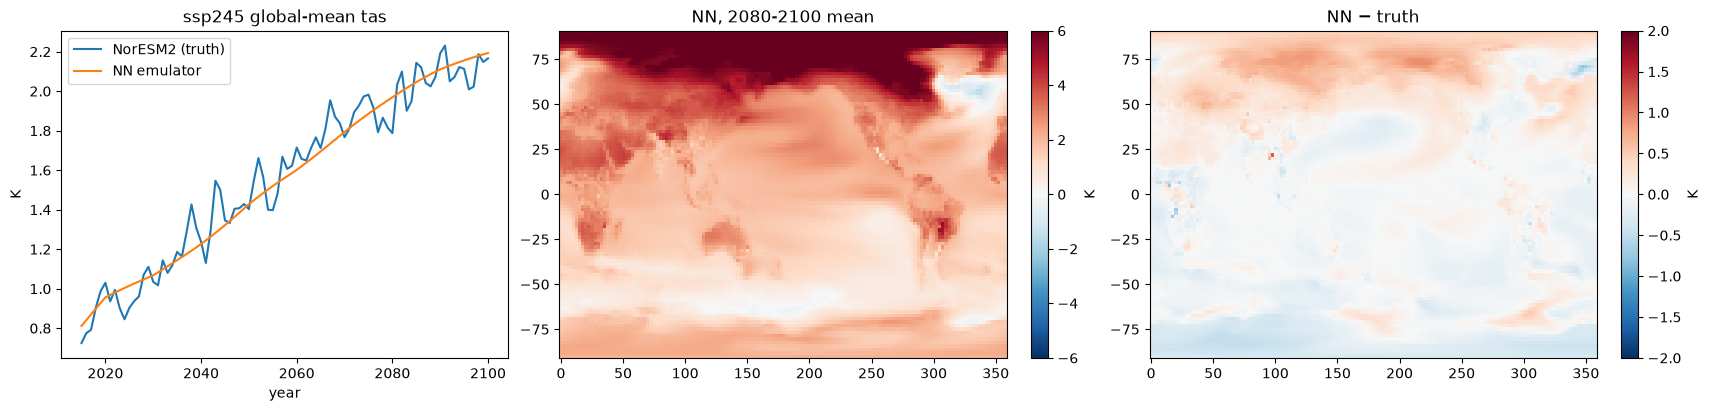

In [12]:
yrs = d["years"]
fig, ax = plt.subplots(1, 3, figsize=(17, 4), constrained_layout=True)
ax[0].plot(yrs, gmean(truth_245), label="NorESM2 (truth)")
ax[0].plot(yrs, gmean(pred_245), label="NN emulator")
ax[0].set(title="ssp245 global-mean tas", xlabel="year", ylabel="K"); ax[0].legend()

sel = (yrs >= START) & (yrs <= END)
t_map, p_map = truth_245[sel].mean(0), pred_245[sel].mean(0)
for a, field, title, cmap, lim in [(ax[1], p_map, "NN, 2080-2100 mean", "RdBu_r", 6),
                                   (ax[2], p_map - t_map, "NN − truth", "RdBu_r", 2)]:
    m = a.pcolormesh(lon, lat, np.asarray(field), cmap=cmap, vmin=-lim, vmax=lim)
    a.set_title(title); plt.colorbar(m, ax=a, label="K")
    

In [13]:
#Gradients of the 2100 global-mean temperature wrt inputs
args = [jnp.asarray(d[k]) for k in ["co2", "ch4", "so2", "bc"]]
J = lambda co2, ch4, so2, bc: gmean(emulate(co2, ch4, so2, bc)[-1])
g_co2, g_ch4, g_so2, g_bc = jax.grad(J, argnums=(0, 1, 2, 3))(*args)
print("dT2100/dCO2 (per unit cumulative CO2, by year), last 5 years:", np.asarray(g_co2[-5:]))
print("dT2100/dSO2 map: shape", g_so2.shape, "| largest |value| in year 2100:", float(jnp.abs(g_so2[-1]).max()))

dT2100/dCO2 (per unit cumulative CO2, by year), last 5 years: [0.         0.         0.         0.         0.00049505]
dT2100/dSO2 map: shape (86, 96, 144) | largest |value| in year 2100: 65268180.0


In [21]:
import os

# Create output dir if it doesn't exist
os.makedirs(OUT, exist_ok=True)

# Also expand ~ in case OUT contains a home-relative path
OUT = os.path.expanduser(OUT)

score_df.to_csv(f"{OUT}/emulator_scores_ssp245.csv")
np.save(f"{OUT}/pred_tas_ssp245.npy", np.asarray(pred_245))

with open(f"{OUT}/emulator.pkl", "wb") as f:
    pickle.dump(jax.device_get({"params": STACKED, "pre": PRE_FROZEN,
                                "nlat": NLAT, "nlon": NLON, "lat": lat, "lon": lon}), f)

In [22]:

score_df.to_csv(f"{OUT}/emulator_scores_ssp245.csv")
np.save(f"{OUT}/pred_tas_ssp245.npy", np.asarray(pred_245))

with open(f"{OUT}/emulator.pkl", "wb") as f:
    pickle.dump(jax.device_get({"params": STACKED, "pre": PRE_FROZEN,
                                "nlat": NLAT, "nlon": NLON, "lat": lat, "lon": lon}), f)

Region mask: 754 grid cells (5.5% of globe)
Scoring window: 2081–2100


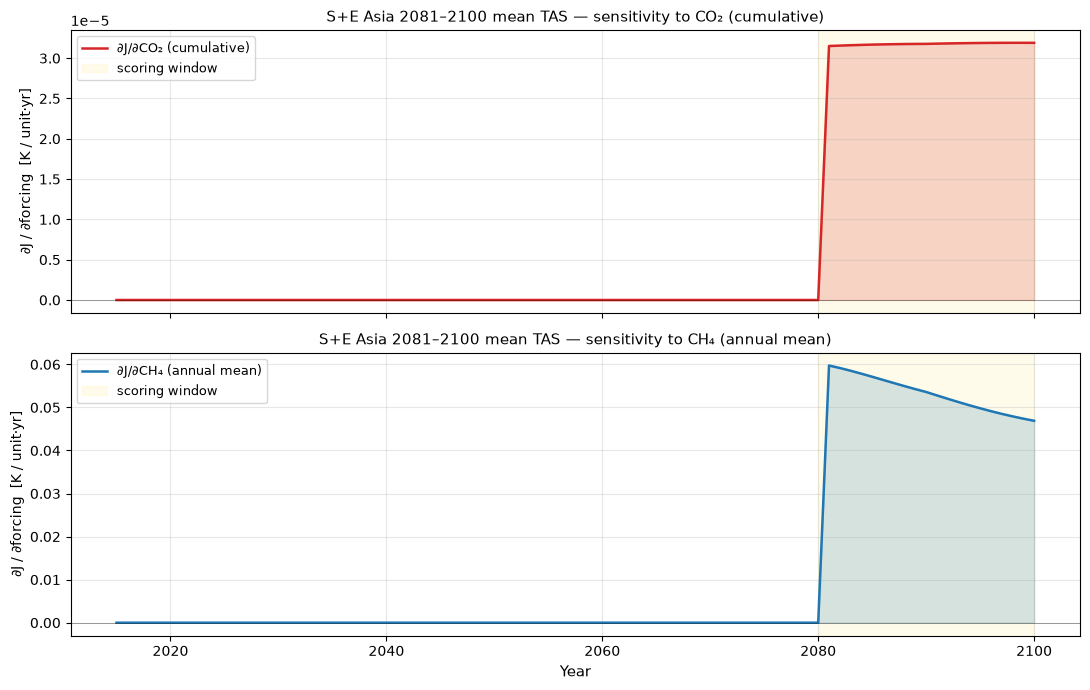

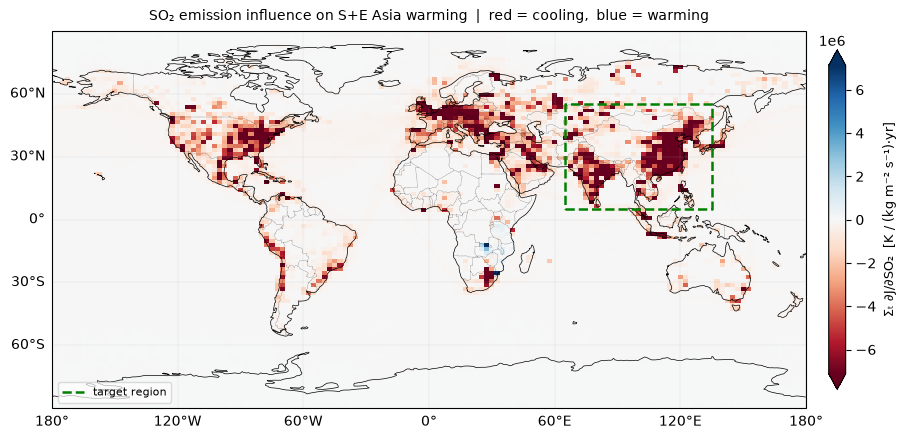

In [30]:
# plotting regional sensitivities to CO2, SO2

import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.colors import TwoSlopeNorm

# South, South east asian region
LAT_MIN, LAT_MAX =  5.0, 55.0   # N covers India through N. China
LON_MIN, LON_MAX = 65.0, 135.0  # E covers Pakistan through E. China

d245      = data[TEST]
lat_245   = d245["lat"]
lon_245   = d245["lon"]
years_245 = d245["years"]

co2_raw = jnp.asarray(d245["co2"])
ch4_raw = jnp.asarray(d245["ch4"])
so2_raw = jnp.asarray(d245["so2"])
bc_raw  = jnp.asarray(d245["bc"])

region_mask = (
    (lat_245[:, None] >= LAT_MIN) & (lat_245[:, None] <= LAT_MAX) &
    (lon_245[None, :] >= LON_MIN) & (lon_245[None, :] <= LON_MAX)
).astype(np.float32)

cos_lat   = np.cos(np.deg2rad(lat_245))[:, None]
weights   = region_mask * cos_lat
weights_j = jnp.array(weights / weights.sum())

n_cells = int(region_mask.sum())
print(f"Region mask: {n_cells} grid cells ({n_cells / (NLAT*NLON)*100:.1f}% of globe)")


score_idx = np.where((years_245 > START) & (years_245 <= END))[0]
print(f"Scoring window: {years_245[score_idx[0]]}–{years_245[score_idx[-1]]}")

# ── 3.2  Scalar J & gradients ─────────────────────────────────────────────────
def scalar_J(co2, ch4, so2, bc):
    tas   = emulate(co2, ch4, so2, bc)
    tas_w = tas[score_idx]
    return jnp.mean(jnp.sum(tas_w * weights_j[None], axis=(1, 2)))

grad_J = jax.jit(jax.grad(scalar_J, argnums=(0, 1, 2, 3)))
g_co2, g_ch4, g_so2, g_bc = grad_J(co2_raw, ch4_raw, so2_raw, bc_raw)

dJ_dco2     = np.array(g_co2)
dJ_dch4     = np.array(g_ch4)
dJ_dso2     = np.array(g_so2)          # (T, NLAT, NLON)
dJ_dso2_sum = dJ_dso2.sum(axis=0)      # (NLAT, NLON)

# ── 3.3  Plot 1 — CO₂ & CH₄ sensitivity vs year ──────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

for ax, (name, sens, color) in zip(axes, [
    ("CO₂ (cumulative)",  dJ_dco2, "#d62728"),
    ("CH₄ (annual mean)", dJ_dch4, "#1f77b4"),
]):
    ax.fill_between(years_245, 0, sens, alpha=0.2, color=color)
    ax.plot(years_245, sens, color=color, lw=1.8, label=f"∂J/∂{name}")
    ax.axvspan(START, END, alpha=0.08, color="gold", label="scoring window")
    ax.axhline(0, lw=0.6, color="k", alpha=0.4)
    ax.set_ylabel("∂J / ∂forcing  [K / unit·yr]", fontsize=10)
    ax.set_title(f"S+E Asia 2081–2100 mean TAS — sensitivity to {name}", fontsize=11)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Year", fontsize=11)
plt.tight_layout()
plt.savefig(f"{OUT}/fig3_co2_ch4_sensitivity_sea.png", dpi=150, bbox_inches="tight")
plt.show()

# ── 3.4  Plot 2 — Cumulative SO₂ spatial sensitivity (clean version) ──────────
vmax = float(np.nanpercentile(np.abs(dJ_dso2_sum), 98))
norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)

fig = plt.figure(figsize=(12, 4.5))
ax  = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())

im = ax.pcolormesh(
    lon_245, lat_245, dJ_dso2_sum,
    transform=ccrs.PlateCarree(),
    cmap="RdBu", norm=norm, shading="auto"
)

# Region box
ax.plot(
    [LON_MIN, LON_MAX, LON_MAX, LON_MIN, LON_MIN],
    [LAT_MIN, LAT_MIN, LAT_MAX, LAT_MAX, LAT_MIN],
    transform=ccrs.PlateCarree(),
    color="green", lw=1.8, ls="--", label="target region"
)

ax.add_feature(cfeature.COASTLINE,         lw=0.5)
ax.add_feature(cfeature.BORDERS,           lw=0.3, linestyle=":")
ax.add_feature(cfeature.LAND,              facecolor="none", edgecolor="none")

# Zoom on the action — extend a bit past the region box
# ax.set_extent([30, 160, -15, 70], crs=ccrs.PlateCarree())

gl = ax.gridlines(draw_labels=True, lw=0.3, alpha=0.4, x_inline=False, y_inline=False)
gl.top_labels   = False
gl.right_labels = False

cbar = plt.colorbar(im, ax=ax, orientation="vertical",
                    pad=0.02, fraction=0.03, extend="both", shrink=0.9)
cbar.set_label("Σₜ ∂J/∂SO₂  [K / (kg m⁻² s⁻¹)·yr]", fontsize=9)

ax.set_title(
    "SO₂ emission influence on S+E Asia warming  |  red = cooling,  blue = warming",
    fontsize=10, pad=8
)
ax.legend(loc="lower left", fontsize=8, framealpha=0.7)

plt.tight_layout()
plt.savefig(f"{OUT}/fig3_so2_sensitivity_sea.png", dpi=150, bbox_inches="tight")
plt.show()